In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

In [73]:
df = pd.read_csv('features.csv')
df = df.sort_values(['Date', 'Store'])

# Calculate Log Sales
Y_raw = df.pivot(index='Date', columns='Store', values='Weekly_Sales').values 
Y_log = np.log1p(Y_raw)

# We want to predict: Change = Log(t) - Log(t-1)
Y_diff = np.diff(Y_log, axis=0) # This makes the data Stationary

# The "Base" is the value at (t-1) which we add the change to
Y_base = Y_log[:-1] # Corresponds to the "previous" step for every diff

# Align X with Y_diff (drop first row of X because diff lost one row)
feature_cols = [c for c in df.columns if c not in ['Date', 'Store', 'Weekly_Sales', 'sales_log1p']]
scaler_x = StandardScaler()
# Reshape X to (Time, Nodes, Feats)
num_dates = df['Date'].nunique()
num_stores = df['Store'].nunique()
X_all_raw = df[feature_cols].values.reshape(num_dates, num_stores, len(feature_cols))
X_all = scaler_x.fit_transform(X_all_raw.reshape(-1, len(feature_cols))).reshape(num_dates, num_stores, -1)

# Drop first row of X to match Y_diff length
X_all = X_all[1:] 

In [74]:
import torch
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

# 1. Define Split (Train on first ~80%, Test on last ~20%)
TRAIN_SPLIT = int(len(Y_diff) * 0.8)
WINDOW_SIZE = 12

# Inputs
X_train = X_all[:TRAIN_SPLIT]
X_test = X_all[TRAIN_SPLIT:]

# Targets (The DIFFERENCE, not the Log)
Y_train_diff = Y_diff[:TRAIN_SPLIT]
Y_test_diff = Y_diff[TRAIN_SPLIT:]

# Bases (The Log Value at t-1) - Do NOT scale this, we just add it back later
Base_train = Y_base[:TRAIN_SPLIT]
Base_test = Y_base[TRAIN_SPLIT:]

# Scale the Targets (Differences are small, roughly -0.5 to 0.5)
scaler_y = StandardScaler()
Y_train_scaled = scaler_y.fit_transform(Y_train_diff)
Y_test_scaled = scaler_y.transform(Y_test_diff)

# Dataset Creator
def create_dataset(x, y, base, window):
    X_seq, Y_seq, Base_seq = [], [], []
    # We need to predict t+1 given t..t-window
    # But 'y' is already aligned such that y[i] is the target for x[i]
    # Wait! Standard windowing: Input [t-w : t], Target [t]
    for i in range(len(x) - window):
        X_seq.append(x[i : i + window])
        Y_seq.append(y[i + window])      # Predict Diff at this step
        Base_seq.append(base[i + window]) # Keep Base at this step for reconstruction
    return np.array(X_seq), np.array(Y_seq), np.array(Base_seq)

X_train_win, Y_train_win, _ = create_dataset(X_train, Y_train_scaled, Base_train, WINDOW_SIZE)
X_test_win, Y_test_win, Base_test_win = create_dataset(X_test, Y_test_scaled, Base_test, WINDOW_SIZE)
# 4. PyTorch Loaders
# The model expects (Batch, Features, Nodes, Time)
# But we have (Batch, Time, Nodes, Features) -> We must permute
tensor_x_train = torch.FloatTensor(X_train_win).permute(0, 3, 2, 1) 
tensor_y_train = torch.FloatTensor(Y_train_win)

tensor_x_test = torch.FloatTensor(X_test_win).permute(0, 3, 2, 1)
tensor_y_test = torch.FloatTensor(Y_test_win)

train_loader = DataLoader(TensorDataset(
    torch.FloatTensor(X_train_win).permute(0, 3, 2, 1), 
    torch.FloatTensor(Y_train_win)
), batch_size=32, shuffle=True)

test_loader = DataLoader(TensorDataset(
    torch.FloatTensor(X_test_win).permute(0, 3, 2, 1), 
    torch.FloatTensor(Y_test_win),
    torch.FloatTensor(Base_test_win)
), batch_size=32, shuffle=False)

print(f"Input Batch Shape: {tensor_x_train.shape}") 
# Expected: (Samples, 34, 45, 12) -> (Batch, Feats, Nodes, Time)

Input Batch Shape: torch.Size([101, 34, 45, 12])


In [75]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class GraphLearner(nn.Module):
    def __init__(self, num_nodes, dim):
        super().__init__()
        # Learnable embeddings for the 45 stores
        self.emb1 = nn.Embedding(num_nodes, dim)
        self.emb2 = nn.Embedding(num_nodes, dim)
        self.lin1 = nn.Linear(dim, dim)
        self.lin2 = nn.Linear(dim, dim)

    def forward(self):
        # Calculate similarity between stores
        nodevec1 = self.lin1(self.emb1.weight)
        nodevec2 = self.lin2(self.emb2.weight)
        # A = ReLU(E1 * E2^T) -> Adjacency Matrix
        adj = F.softmax(F.relu(torch.mm(nodevec1, nodevec2.transpose(0, 1))), dim=1)
        return adj

In [76]:
class TemporalGNN(nn.Module):
    def __init__(self, num_nodes, in_channels, out_channels, window_size):
        super().__init__()
        self.num_nodes = num_nodes
        
        # 1. Graph Learner: Learns relations between the 45 stores
        self.graph_learner = GraphLearner(num_nodes, dim=40)
        
        # 2. Input Projection
        self.start_conv = nn.Conv2d(in_channels, 32, kernel_size=(1,1))
        
        # 3. Temporal Block (Dilated Convolutions)
        # Captures trends like "lag_52" efficiently
        self.tcn = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=(1, 3), dilation=1, padding=(0,1)),
            nn.GELU(),
            nn.Conv2d(64, 32, kernel_size=(1, 3), dilation=2, padding=(0,2))
        )
        
        # 4. Graph Convolution (Spatial Block)
        # Aggregates info from correlated stores
        self.gcn_weight = nn.Parameter(torch.randn(32, 32))
        
        # 5. Output Projection
        self.end_conv = nn.Conv2d(32, out_channels, kernel_size=(1,1))
        
    def forward(self, x):
        # x shape: (Batch, Features, Nodes, Time)
        
        # 1. Learn the Graph
        adj = self.graph_learner() # [45, 45]
        
        # 2. Initial Feature Extraction
        x = self.start_conv(x)
        skip = x
        
        # 3. Temporal Processing
        x = self.tcn(x)
        
        # 4. Spatial Processing (Manual GCN implementation for simplicity)
        # AXW operation: Propagate info across the learned graph
        # (Batch, Channels, Nodes, Time) -> Permute for matmul
        B, C, N, T = x.shape
        x_reshape = x.permute(0, 3, 2, 1).reshape(B*T, N, C) 
        # Graph Conv: Adj * X * Weight
        out = torch.matmul(adj, x_reshape) 
        out = torch.matmul(out, self.gcn_weight)
        
        x = out.reshape(B, T, N, C).permute(0, 3, 2, 1) + skip # Residual connection
        
        # 5. Final Prediction
        # We usually take the last time step to predict the future
        x = x[:, :, :, -1:] 
        x = self.end_conv(x)
        return x # Shape: (Batch, 1, 45, 1) -> Prediction for each store

In [77]:
# Hyperparameters
num_nodes = 45
in_channels = X_all.shape[2] # ~34 features
out_channels = 1 # Predicting 1 value (Sales)
window_size = WINDOW_SIZE

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = TemporalGNN(num_nodes, in_channels, out_channels, window_size).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="min", patience=5,factor=0.5)
criterion = torch.nn.SmoothL1Loss() # MAE is better for Sales than MSE

In [ ]:
import os

epochs = 150
train_losses = []
test_losses = []

for epoch in range(epochs):
    # --- Training ---
    model.train()
    batch_loss = []
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        
        optimizer.zero_grad()
        
        # Forward pass
        # Output shape: (Batch, 1, Nodes, 1) -> Squeeze to (Batch, Nodes)
        pred = model(bx).squeeze(-1).squeeze(1)
        
        loss = criterion(pred, by)
        loss.backward()
        optimizer.step()
        
        batch_loss.append(loss.item())
    
    train_avg = np.mean(batch_loss)
    train_losses.append(train_avg)

    # --- Validation ---
    model.eval()
    val_batch_loss = []
    with torch.no_grad():
        for bx, by,_ in test_loader:
            bx, by = bx.to(device), by.to(device)
            pred = model(bx).squeeze(-1).squeeze(1)
            loss = criterion(pred, by)
            val_batch_loss.append(loss.item())
    
    val_loss = np.mean(val_batch_loss)
    scheduler.step(val_loss)
    test_avg = np.mean(val_batch_loss)
    test_losses.append(test_avg)
    
    if epoch % 10 == 0:
        print(f"Epoch {epoch}: Train MAE={train_avg:.4f}, Test MAE={test_avg:.4f}")

# Save model + training artifacts
os.makedirs('checkpoints', exist_ok=True)
checkpoint = {
    'epoch': epochs,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'train_losses': train_losses,
    'test_losses': test_losses,
    'scaler_x': scaler_x,
    'scaler_y': scaler_y,
}
torch.save(checkpoint, 'checkpoints/temporal_gnn_checkpoint.pt')
# Save full model object for easy reload (optional)
torch.save(model, 'checkpoints/temporal_gnn_full_model.pth')

print("Saved checkpoint to 'checkpoints/temporal_gnn_checkpoint.pt' and full model to 'checkpoints/temporal_gnn_full_model.pth'")

Epoch 0: Train MAE=0.3107, Test MAE=0.1493
Epoch 10: Train MAE=0.2742, Test MAE=0.1370
Epoch 20: Train MAE=0.2398, Test MAE=0.1569
Epoch 30: Train MAE=0.2028, Test MAE=0.1450
Epoch 40: Train MAE=0.1949, Test MAE=0.1373
Epoch 50: Train MAE=0.1977, Test MAE=0.1374
Epoch 60: Train MAE=0.1929, Test MAE=0.1374
Epoch 70: Train MAE=0.2138, Test MAE=0.1374
Epoch 80: Train MAE=0.1970, Test MAE=0.1374
Epoch 90: Train MAE=0.1908, Test MAE=0.1374


In [ ]:
model.eval()
preds_diff_scaled = []
actuals_diff_scaled = []
bases = []

with torch.no_grad():
    for bx, by, base in test_loader:
        bx = bx.to(device)
        preds_diff_scaled.append(model(bx).squeeze().cpu().numpy())
        actuals_diff_scaled.append(by.numpy())
        bases.append(base.numpy())

# Concat
preds_diff_scaled = np.concatenate(preds_diff_scaled)
bases = np.concatenate(bases)
actuals_diff_scaled = np.concatenate(actuals_diff_scaled)

# A. Inverse Scale the "Difference"
preds_diff = scaler_y.inverse_transform(preds_diff_scaled)
actuals_diff = scaler_y.inverse_transform(actuals_diff_scaled)

# B. Reconstruct Log Sales: Log(t) = Log(t-1) + Diff(t)
preds_log = bases + preds_diff
actuals_log = bases + actuals_diff

# C. Inverse Log (Back to Real Dollars)
preds_dollar = np.expm1(preds_log)
actuals_dollar = np.expm1(actuals_log)

# Metrics
mape = np.mean(np.abs((actuals_dollar - preds_dollar) / actuals_dollar)) * 100
print(f"\nFINAL STATIONARY MAPE: {mape:.2f}%")


FINAL STATIONARY MAPE: 5.07%
Store 36 MAPE: 5.20%


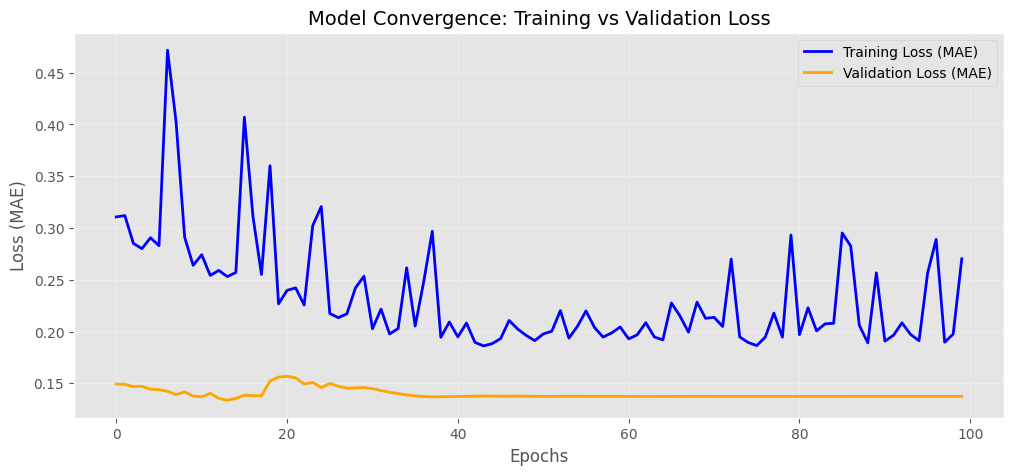

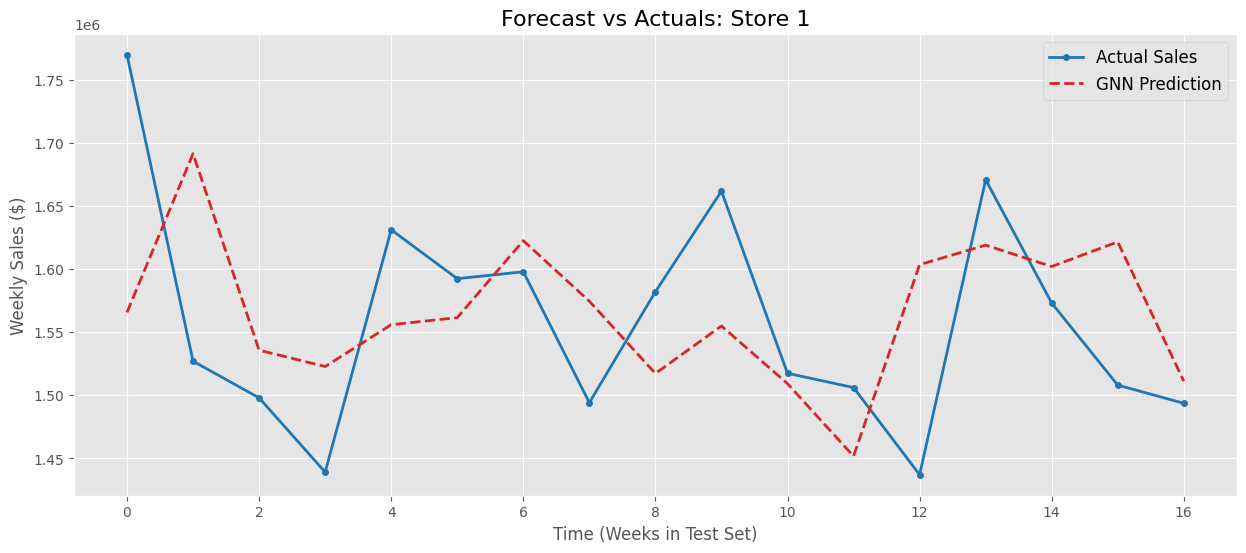

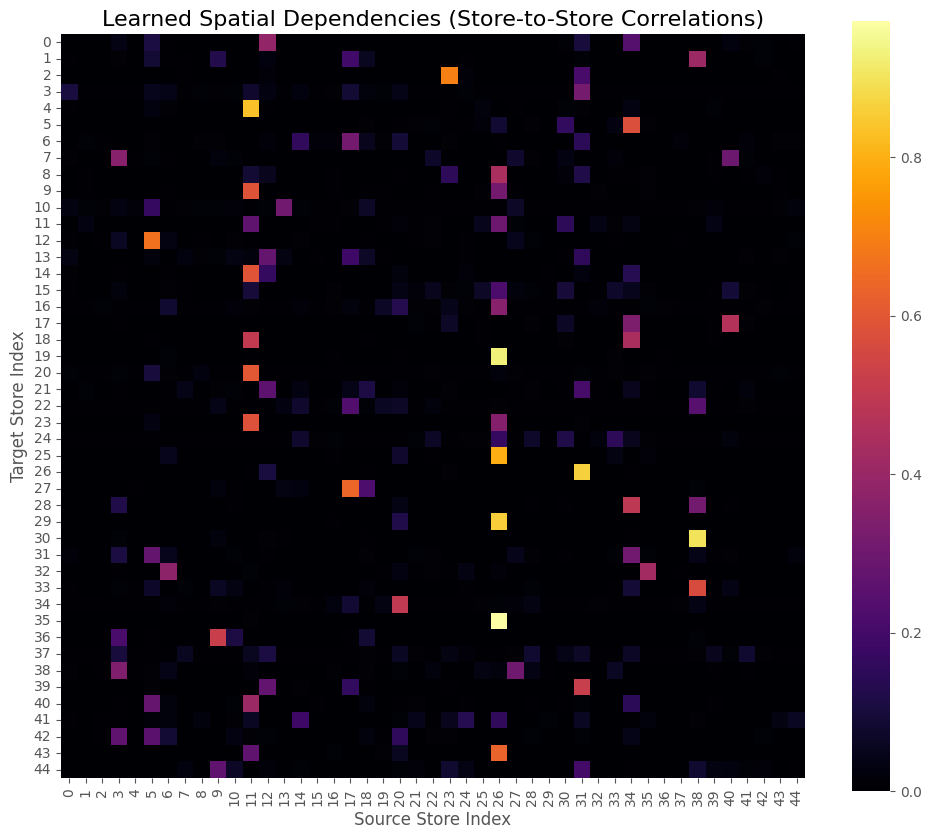

Top 5 Stores influencing Store 1:
- Store 13 (Strength: 0.3845)
- Store 35 (Strength: 0.2417)
- Store 6 (Strength: 0.1083)
- Store 32 (Strength: 0.1013)
- Store 4 (Strength: 0.0363)
- Store 41 (Strength: 0.0258)


In [80]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set a nice style
plt.style.use('ggplot') 

# ==========================================
# Plot 1: Training vs Validation Loss
# Checks for overfitting and convergence
# ==========================================
plt.figure(figsize=(12, 5))
plt.plot(train_losses, label='Training Loss (MAE)', linewidth=2, color='blue')
plt.plot(test_losses, label='Validation Loss (MAE)', linewidth=2, color='orange')
plt.title('Model Convergence: Training vs Validation Loss', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Loss (MAE)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ==========================================
# Plot 2: Actual vs Predicted Sales (Specific Store)
# Visually inspect how well the model tracks trends
# ==========================================
store_idx = 0  # Change this (0-44) to see different stores
subset_len = 50 # View last 50 weeks for clarity

plt.figure(figsize=(15, 6))
plt.plot(actuals_dollar[-subset_len:, store_idx], label='Actual Sales', marker='o', markersize=4, linewidth=2, color='tab:blue')
plt.plot(preds_dollar[-subset_len:, store_idx], label='GNN Prediction', linestyle='--', linewidth=2, color='tab:red')
plt.title(f'Forecast vs Actuals: Store {store_idx+1}', fontsize=16)
plt.xlabel('Time (Weeks in Test Set)')
plt.ylabel('Weekly Sales ($)')
plt.legend(fontsize=12)
plt.show()

# ==========================================
# Plot 3: The "Brain" of the GNN (Adjacency Matrix)
# Shows which stores the model learned are correlated
# ==========================================
model.eval()
# Extract the learned matrix from the GraphLearner module
adj_matrix = model.graph_learner().detach().cpu().numpy()

plt.figure(figsize=(12, 10))
sns.heatmap(adj_matrix, cmap='inferno', square=True, vmin=0, vmax=np.max(adj_matrix))
plt.title('Learned Spatial Dependencies (Store-to-Store Correlations)', fontsize=16)
plt.xlabel('Source Store Index')
plt.ylabel('Target Store Index')
plt.show()

# ==========================================
# Bonus: Top Correlations
# Find out which stores influence Store 1 the most
# ==========================================
target_store = 0
correlations = adj_matrix[target_store]
# Get top 5 influencing stores (excluding itself)
top_indices = correlations.argsort()[-6:][::-1] # Top 6 (including self)

print(f"Top 5 Stores influencing Store {target_store+1}:")
for idx in top_indices:
    if idx != target_store:
        print(f"- Store {idx+1} (Strength: {correlations[idx]:.4f})")

In [85]:
import pandas as pd
import numpy as np

# 1. Initialize list to store metrics
metrics_list = []

# 2. Loop through each store (0 to 44)
num_stores = actuals_dollar.shape[1]

for i in range(num_stores):
    act = actuals_dollar[:, i]
    pred = preds_dollar[:, i]
    
    # Calculate Metrics
    mae = np.mean(np.abs(pred - act))
    rmse = np.sqrt(np.mean((pred - act)**2))
    # Add small epsilon (1e-6) to avoid division by zero error
    mape = np.mean(np.abs((act - pred) / (act + 1e-6))) * 100
    
    metrics_list.append({
        'Store': i + 1,
        'MAE ($)': mae,
        'RMSE ($)': rmse,
        'MAPE (%)': mape
    })

# 3. Convert to DataFrame for nice formatting
results_df = pd.DataFrame(metrics_list)

# 4. Sort by Accuracy (Lowest MAPE is best)
results_df = results_df.sort_values('MAPE (%)')

# 5. Print the Table
print("="*60)
print("STORE-WISE PERFORMANCE METRICS (Sorted by Accuracy)")
print("="*60)
# Format floats to 2 decimal places with commas for dollars
print(results_df.to_string(index=False, float_format=lambda x: "{:,.2f}".format(x)))
print("="*60)
results_df.to_csv('gnn_results.csv', index=False)

# 6. Print Summary Highlights
best_store = results_df.iloc[0]
worst_store = results_df.iloc[-1]

print(f"\nBest Performing:  Store {int(best_store['Store'])} (MAPE: {best_store['MAPE (%)']:.2f}%)")
print(f"Worst Performing: Store {int(worst_store['Store'])} (MAPE: {worst_store['MAPE (%)']:.2f}%)")

STORE-WISE PERFORMANCE METRICS (Sorted by Accuracy)
 Store    MAE ($)   RMSE ($)  MAPE (%)
    37  11,436.45  13,148.73      2.17
    30  12,070.51  14,478.86      2.79
     5  10,948.42  12,984.38      3.45
    34  33,438.45  42,706.37      3.48
     2  66,029.88  83,341.92      3.55
     8  32,644.98  39,578.85      3.61
    10  64,803.91  78,171.02      3.72
    12  37,037.84  49,255.26      3.89
    31  53,144.33  67,075.68      3.92
    13  80,307.19  99,929.55      3.97
     4  86,438.88 100,013.23      4.06
    15  23,785.24  29,216.50      4.10
     9  22,420.71  25,644.79      4.14
     3  16,833.24  21,441.78      4.15
    43  25,712.57  31,886.12      4.17
    26  44,348.80  57,093.86      4.18
    44  14,661.35  20,007.76      4.29
    32  50,798.46  63,429.00      4.29
    25  30,224.51  36,068.76      4.36
    41  61,234.79  74,850.25      4.41
     6  69,812.48  95,753.95      4.48
    19  65,025.34  86,564.82      4.61
    35  40,428.26  54,237.22      4.64
    39  75,3

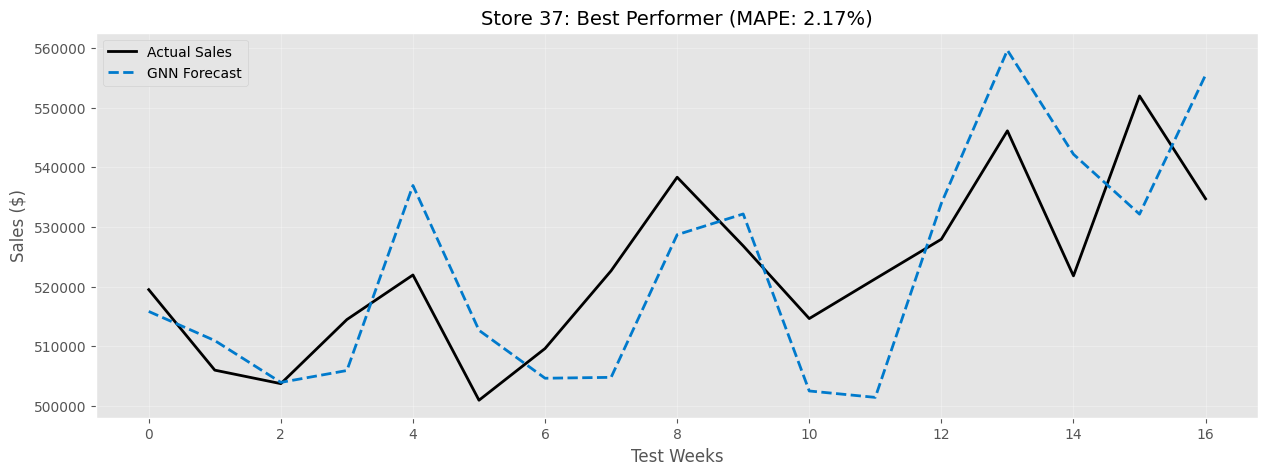

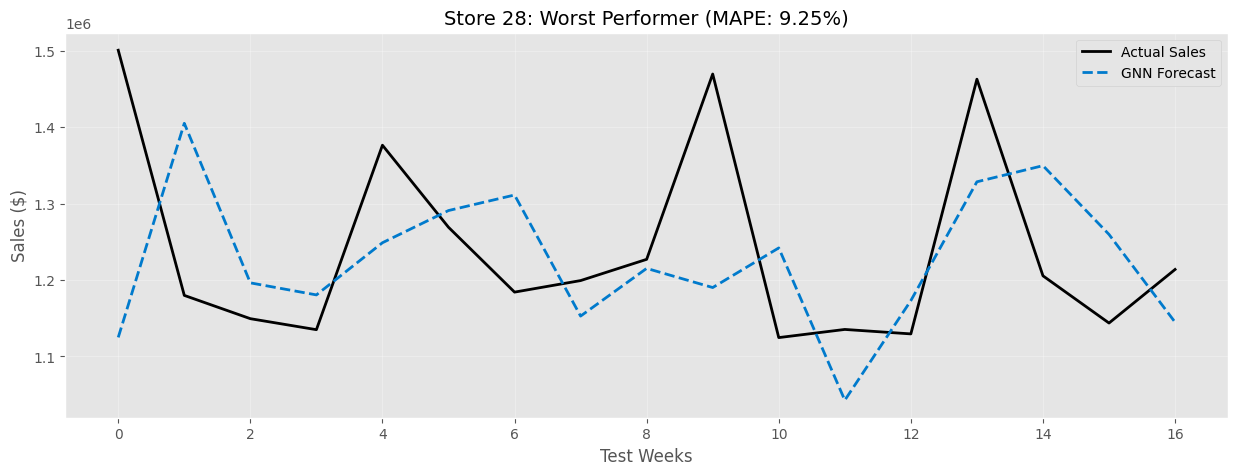

In [84]:
import matplotlib.pyplot as plt

# Helper to plot specific store
def plot_store_forecast(store_id, actuals, preds, title):
    # Find index for store (Store IDs are 1-based, array is 0-based)
    idx = store_id - 1
    
    plt.figure(figsize=(15, 5))
    plt.plot(actuals[:, idx], label='Actual Sales', color='black', linewidth=2)
    plt.plot(preds[:, idx], label='GNN Forecast', color='#007acc', linestyle='--', linewidth=2)
    
    plt.title(f'Store {store_id}: {title}', fontsize=14)
    plt.xlabel('Test Weeks')
    plt.ylabel('Sales ($)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# Plot Best Performer
plot_store_forecast(37, actuals_dollar, preds_dollar, 
                   title="Best Performer (MAPE: 2.17%)")

# Plot Volatile Store (To show improvement)
plot_store_forecast(28, actuals_dollar, preds_dollar, 
                   title="Worst Performer (MAPE: 9.25%)")